# 03 · Churn Classification

**Goal:** predict `y = Churn` and compare five models, handling the class imbalance and
avoiding data leakage.

| Step | Content |
| --- | --- |
| 1 | Baseline models (no imbalance handling), 5-fold CV |
| 2 | Imbalance handling: `class_weight`, Random Oversampling, SMOTE |
| 3 | Final evaluation on the test set: precision, recall, F1, ROC-AUC, confusion matrix |
| 4 | Feature importance |
| 5 | MLflow tracking |

**Metrics.** Churners are the minority class (~26 %):
- **Recall** = share of real churners we detect (missing a churner = lost customer);
- **Precision** = share of predicted churners that really churn (cost of retention offers);
- **F1** = balance between both → main selection metric;
- **ROC-AUC** = ranking quality, independent of the decision threshold.

## Setup
This notebook is **self-contained**: it reloads the raw CSV and redefines the cleaning,
feature-engineering and preprocessing steps (explained in detail in notebook 01), so it
can be run on its own.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA = ROOT / "data" / "raw" / "wa-fn-usec-telco-customer.csv"
MODELS_DIR = ROOT / "models"
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"

RANDOM_STATE = 42
TARGET = "Churn"
ID_COLUMN = "customerID"

### Cleaning & feature engineering
- `clean_raw`: convert `TotalCharges` to numeric (blank → NaN) and drop duplicated profiles.
- `add_features`: row-wise engineered features (no learned statistic → no leakage).

In [2]:
SERVICE_COLUMNS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                   "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def clean_raw(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    return df.drop_duplicates(subset=[c for c in df.columns if c != ID_COLUMN]).reset_index(drop=True)


def add_features(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["num_services"] = (df[SERVICE_COLUMNS] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
    df["avg_monthly_spend"] = np.where(df["tenure"] > 0,
                                       df["TotalCharges"] / df["tenure"].replace(0, np.nan),
                                       df["MonthlyCharges"])
    df["charges_per_service"] = df["MonthlyCharges"] / df["num_services"].clip(lower=1)
    df["is_month_to_month"] = (df["Contract"] == "Month-to-month").astype(int)
    df["auto_payment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)
    df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                                labels=["0-12", "13-24", "25-48", "49-60", "61-72"]).astype(str)
    return df

### Preprocessing
Numeric → median imputation + standardization; binary → unchanged;
categorical → most-frequent imputation + one-hot encoding.

In [3]:
RAW_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
RAW_BINARY = ["SeniorCitizen"]
RAW_CATEGORICAL = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                   "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                   "PaperlessBilling", "PaymentMethod"]

NUMERIC_FEATURES = RAW_NUMERIC + ["num_services", "avg_monthly_spend", "charges_per_service"]
BINARY_FEATURES = RAW_BINARY + ["is_month_to_month", "auto_payment", "has_family", "is_new_customer"]
CATEGORICAL_FEATURES = RAW_CATEGORICAL + ["tenure_group"]

# Subset used for segmentation (no target!)
CLUSTER_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
CLUSTER_BINARY = ["is_month_to_month", "auto_payment", "has_family", "SeniorCitizen"]
CLUSTER_CATEGORICAL = ["InternetService"]


def make_preprocessor(numeric=NUMERIC_FEATURES, binary=BINARY_FEATURES, categorical=CATEGORICAL_FEATURES):
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                          sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, numeric),
                              ("bin", "passthrough", binary),
                              ("cat", categorical_pipe, categorical)],
                             verbose_feature_names_out=False)

### Load data

In [4]:
df = clean_raw(pd.read_csv(RAW_DATA))
print("Dataset:", df.shape)

Dataset: (7021, 21)


### Modelling helpers
- `ClusterFeature`: adds the K-Means `cluster` (k = 4, see notebook 02) as a feature. The
  K-Means is **fitted on the training data only** (refitted on each CV fold).
- `build_pipeline`: raw customer rows → [feature engineering] → [cluster] → preprocessing →
  [oversampling] → model. Because everything lives in one `imblearn` pipeline, imputation,
  scaling and SMOTE/oversampling are fitted on training data only — **no data leakage** —
  and the oversampler is skipped at prediction time.

In [5]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

N_CLUSTERS = 4


def make_cluster_pipeline(n_clusters=N_CLUSTERS):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", make_preprocessor(CLUSTER_NUMERIC, CLUSTER_BINARY, CLUSTER_CATEGORICAL)),
        ("kmeans", KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE)),
    ])


class ClusterFeature(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=N_CLUSTERS):
        self.n_clusters = n_clusters

    def fit(self, X, y=None):
        self.pipeline_ = make_cluster_pipeline(self.n_clusters).fit(X)
        return self

    def transform(self, X):
        X = X.copy()
        X["cluster"] = self.pipeline_.predict(X).astype(str)
        return X


MODEL_NAMES = ["LogisticRegression", "DecisionTree", "RandomForest", "SVM", "XGBoost"]
IMBALANCE_STRATEGIES = ["none", "class_weight", "random_oversampling", "smote"]


def make_model(name, strategy="none", pos_weight=1.0):
    cw = "balanced" if strategy == "class_weight" else None
    model = {
        "LogisticRegression": lambda: LogisticRegression(max_iter=2000, class_weight=cw),
        "DecisionTree": lambda: DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE),
        "RandomForest": lambda: RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                       random_state=RANDOM_STATE, n_jobs=1),
        "SVM": lambda: SVC(class_weight=cw, random_state=RANDOM_STATE),
        "XGBoost": lambda: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
                                         scale_pos_weight=pos_weight if strategy == "class_weight" else 1.0),
    }[name]()
    sampler = {"random_oversampling": RandomOverSampler(random_state=RANDOM_STATE),
               "smote": SMOTE(random_state=RANDOM_STATE)}.get(strategy)
    return model, sampler


def build_pipeline(name, strategy="none", pos_weight=1.0, n_clusters=None, feature_engineering=True):
    model, sampler = make_model(name, strategy, pos_weight)
    steps = []
    if feature_engineering:
        steps.append(("features", FunctionTransformer(add_features)))
        num, binary, cat = NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES
    else:
        num, binary, cat = RAW_NUMERIC, RAW_BINARY, RAW_CATEGORICAL
    if n_clusters:
        steps.append(("cluster", ClusterFeature(n_clusters)))
        cat = cat + ["cluster"]
    steps.append(("preprocess", make_preprocessor(num, binary, cat)))
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", model))
    return ImbPipeline(steps)


def predict_scores(model, X):
    """Churn probability, or decision score for SVM (enough for ROC-AUC)."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


def evaluate(model, X, y):
    y_pred = model.predict(X)
    return {"precision": precision_score(y, y_pred), "recall": recall_score(y, y_pred),
            "f1": f1_score(y, y_pred), "roc_auc": roc_auc_score(y, predict_scores(model, X))}


def cv_scores(pipeline, X, y, cv):
    scores = cross_validate(pipeline, X, y, cv=cv, n_jobs=-1,
                            scoring=["precision", "recall", "f1", "roc_auc"])
    return {m: scores[f"test_{m}"].mean() for m in ["precision", "recall", "f1", "roc_auc"]}

### Train / test split
Same stratified 80/20 split (same `random_state`) in every notebook. The test set is
only used for the final evaluation; model selection uses 5-fold cross-validation on train.

In [6]:
X = df.drop(columns=[ID_COLUMN, TARGET])
y = (df[TARGET] == "Yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()   # for XGBoost scale_pos_weight
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Train {X_train.shape}, Test {X_test.shape}, churn rate train {y_train.mean():.3f}")

Train (5616, 19), Test (1405, 19), churn rate train 0.264


### MLflow helpers
Each run logs: model hyperparameters, preprocessing parameters, metrics, figures and the
fitted pipeline. Runs are stored in `mlflow.db` / `mlruns/` at the project root
(UI: `mlflow ui --backend-store-uri sqlite:///mlflow.db`).

In [7]:
import logging

import mlflow
import mlflow.sklearn

logging.getLogger("mlflow").setLevel(logging.ERROR)


def setup_mlflow(experiment_name):
    mlflow.set_tracking_uri(MLFLOW_URI)
    if mlflow.get_experiment_by_name(experiment_name) is None:
        mlflow.create_experiment(experiment_name,
                                 artifact_location=(ROOT / "mlruns" / experiment_name).as_uri())
    mlflow.set_experiment(experiment_name)


def preprocessing_params(pipeline):
    steps = dict(pipeline.steps)
    return {"feature_engineering": "features" in steps, "cluster_feature": "cluster" in steps,
            "numeric_imputer": "median", "categorical_imputer": "most_frequent",
            "scaler": "StandardScaler", "encoder": "OneHotEncoder",
            "resampling": type(steps["sampler"]).__name__ if "sampler" in steps else "none"}


def log_run(run_name, pipeline, metrics, params=None, figures=None, tags=None, log_model=True):
    with mlflow.start_run(run_name=run_name) as run:
        model = pipeline.named_steps["model"]
        hp = {k: v for k, v in model.get_params().items() if v is None or isinstance(v, (str, int, float, bool))}
        mlflow.log_param("model", type(model).__name__)
        mlflow.log_params({f"model__{k}": v for k, v in hp.items()})
        mlflow.log_params({f"prep__{k}": v for k, v in preprocessing_params(pipeline).items()})
        mlflow.log_params(params or {})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
        mlflow.set_tags(tags or {})
        for name, fig in (figures or {}).items():
            mlflow.log_figure(fig, f"{name}.png")
        if log_model:
            mlflow.sklearn.log_model(pipeline, name="model", serialization_format="cloudpickle",
                                     input_example=X_train.head(3))
        return run.info.run_id

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

setup_mlflow("tele-cluster-classification")

## 1. Baseline models (no imbalance handling)
Each model is evaluated with **5-fold stratified cross-validation on the training set**.
The whole pipeline (feature engineering → imputation → scaling → encoding → model) is
refitted on each training fold, so validation folds never influence the preprocessing.

In [9]:
baseline = pd.DataFrame({name: cv_scores(build_pipeline(name, "none"), X_train, y_train, cv)
                         for name in MODEL_NAMES}).T
baseline.round(3)

,precision,recall,f1,roc_auc
LogisticRegression,0.670,0.528,0.590,0.847
DecisionTree,0.475,0.492,0.483,0.649
RandomForest,0.634,0.492,0.554,0.828
SVM,0.674,0.483,0.562,0.797
XGBoost,0.641,0.526,0.578,0.841


Without rebalancing, the models favour the majority class: precision is decent but
**recall stays around 0.5** — half of the churners are missed. The Decision Tree overfits
(lowest ROC-AUC) because it is grown without depth limit.

## 2. Handling class imbalance
Three techniques are compared, always **applied to the training data only**:
- `class_weight="balanced"`: errors on churners cost more in the loss function
  (for XGBoost: `scale_pos_weight = #negatives / #positives`);
- **Random Oversampling**: duplicates random churners until classes are balanced;
- **SMOTE**: creates synthetic churners by interpolating between neighbours.

The oversamplers are `imblearn` pipeline steps: during cross-validation they only
resample the training folds — validation folds and the test set keep their real distribution.

In [10]:
rows = []
for name in MODEL_NAMES:
    for strategy in IMBALANCE_STRATEGIES:
        scores = cv_scores(build_pipeline(name, strategy, POS_WEIGHT), X_train, y_train, cv)
        rows.append({"model": name, "strategy": strategy, **scores})
imbalance = pd.DataFrame(rows)
imbalance.pivot(index="model", columns="strategy", values="f1")[IMBALANCE_STRATEGIES].round(3)

strategy,none,class_weight,random_oversampling,smote
model,,,,
DecisionTree,0.483,0.482,0.481,0.506
LogisticRegression,0.590,0.631,0.631,0.628
RandomForest,0.554,0.614,0.594,0.591
SVM,0.562,0.630,0.623,0.623
XGBoost,0.578,0.624,0.629,0.606


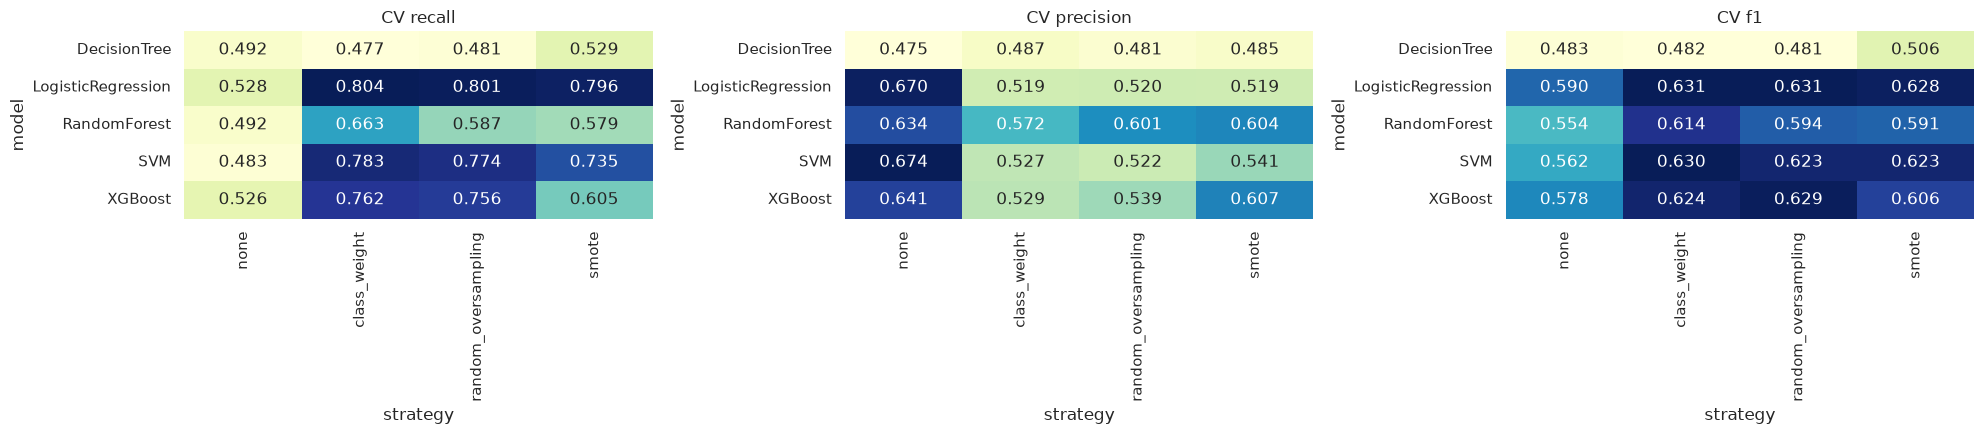

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, metric in zip(axes, ["recall", "precision", "f1"]):
    table = imbalance.pivot(index="model", columns="strategy", values=metric)[IMBALANCE_STRATEGIES]
    sns.heatmap(table, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, cbar=False)
    ax.set_title(f"CV {metric}")
plt.tight_layout()
plt.show()

All three techniques **raise recall strongly** (≈0.5 → ≈0.75–0.80 for Logistic Regression,
SVM and XGBoost) at the cost of some precision, which improves F1. ROC-AUC barely changes:
rebalancing does not make the model rank customers better, it moves the decision boundary
in favour of churners.

We keep, for each model, the strategy with the best CV F1:

In [12]:
best_strategy = (imbalance.sort_values("f1", ascending=False)
                 .drop_duplicates("model").set_index("model").loc[MODEL_NAMES])
best_strategy.round(3)

,strategy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,random_oversampling,0.520,0.801,0.631,0.847
DecisionTree,smote,0.485,0.529,0.506,0.664
RandomForest,class_weight,0.572,0.663,0.614,0.830
SVM,class_weight,0.527,0.783,0.630,0.827
XGBoost,random_oversampling,0.539,0.756,0.629,0.840


## 3. Evaluation on the test set
Each model (with its best strategy) is refitted on the whole training set and evaluated
once on the held-out test set.

In [13]:
fitted, test_rows = {}, []
for name in MODEL_NAMES:
    strategy = best_strategy.loc[name, "strategy"]
    pipe = build_pipeline(name, strategy, POS_WEIGHT).fit(X_train, y_train)
    fitted[name] = pipe
    test_rows.append({"model": name, "strategy": strategy, **evaluate(pipe, X_test, y_test)})
test_results = pd.DataFrame(test_rows).set_index("model").sort_values("f1", ascending=False)
test_results.round(3)

,strategy,precision,recall,f1,roc_auc
model,,,,,
SVM,class_weight,0.533,0.769,0.629,0.826
LogisticRegression,random_oversampling,0.519,0.780,0.623,0.841
XGBoost,random_oversampling,0.536,0.739,0.621,0.835
RandomForest,class_weight,0.561,0.634,0.595,0.826
DecisionTree,smote,0.509,0.511,0.510,0.671


### Confusion matrices

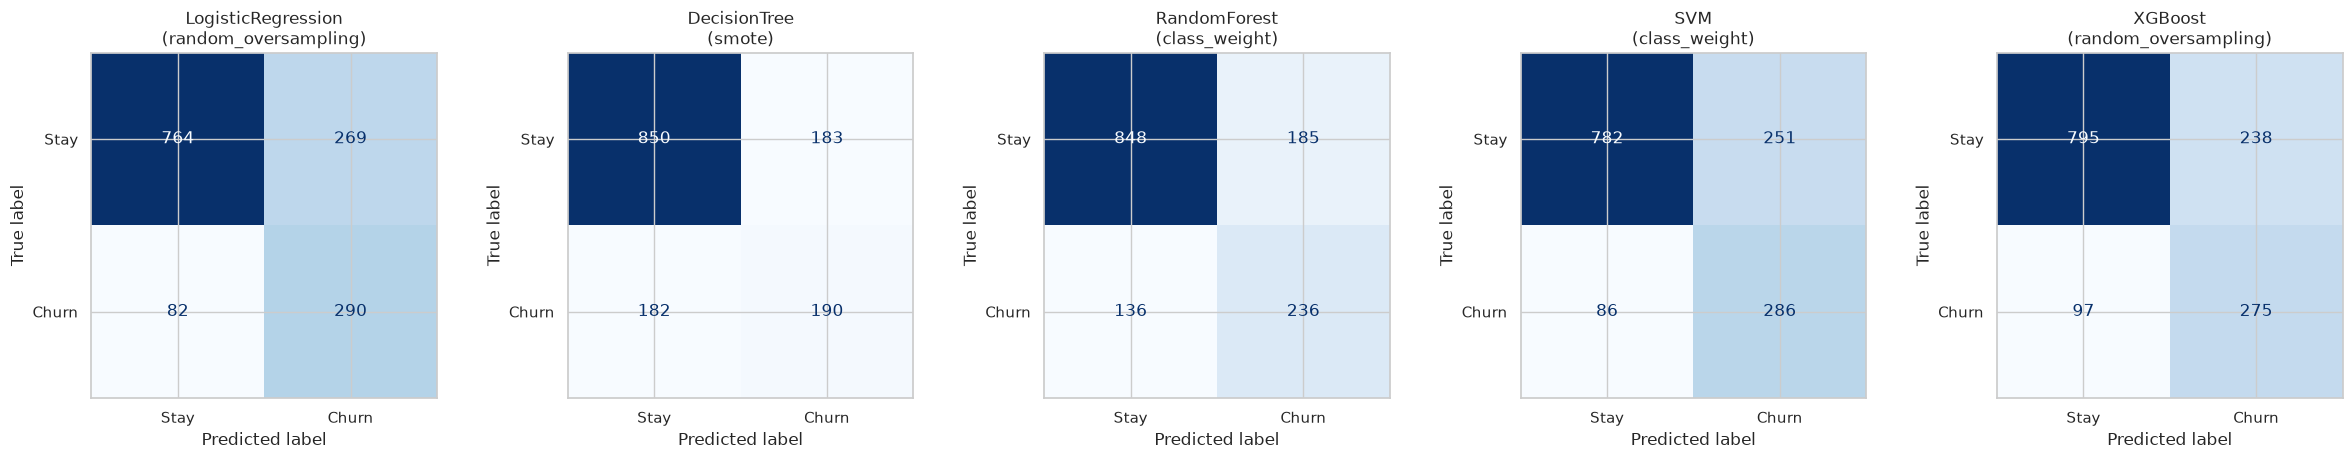

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, display_labels=["Stay", "Churn"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}\n({best_strategy.loc[name, 'strategy']})")
plt.tight_layout()
plt.show()

### ROC curves

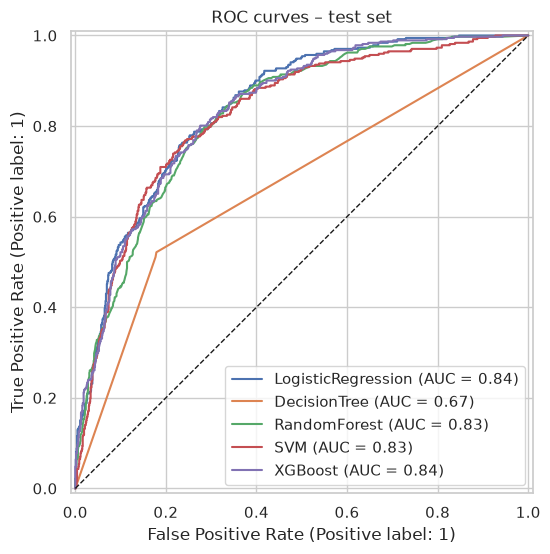

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in MODEL_NAMES:
    RocCurveDisplay.from_predictions(y_test, predict_scores(fitted[name], X_test), name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("ROC curves – test set")
roc_fig = fig
plt.show()

In [16]:
best_name = test_results.index[0]
print(f"Best model on test F1: {best_name}\n")
print(classification_report(y_test, fitted[best_name].predict(X_test), target_names=["Stay", "Churn"]))

Best model on test F1: SVM

              precision    recall  f1-score   support

        Stay       0.90      0.76      0.82      1033
       Churn       0.53      0.77      0.63       372

    accuracy                           0.76      1405
   macro avg       0.72      0.76      0.73      1405
weighted avg       0.80      0.76      0.77      1405



**Reading the results**
- Logistic Regression, SVM and XGBoost are the strongest (test F1 ≈ 0.62–0.63, ROC-AUC ≈ 0.83–0.84).
  The relations in this dataset are largely linear/additive, so a simple, well-regularised
  model is as good as complex ones.
- With rebalancing, about **4 churners out of 5 are detected**, with roughly one false
  alarm per true churner detected — acceptable for a retention campaign, where contacting
  a loyal customer costs much less than losing a churner.
- The unconstrained Decision Tree is clearly the weakest (overfitting) — fixed by tuning
  `max_depth` in notebook 05.

## 4. Feature importance
Which variables drive churn? Coefficients of the Logistic Regression (on standardized
features: sign = direction, magnitude = strength) and impurity importance of XGBoost.

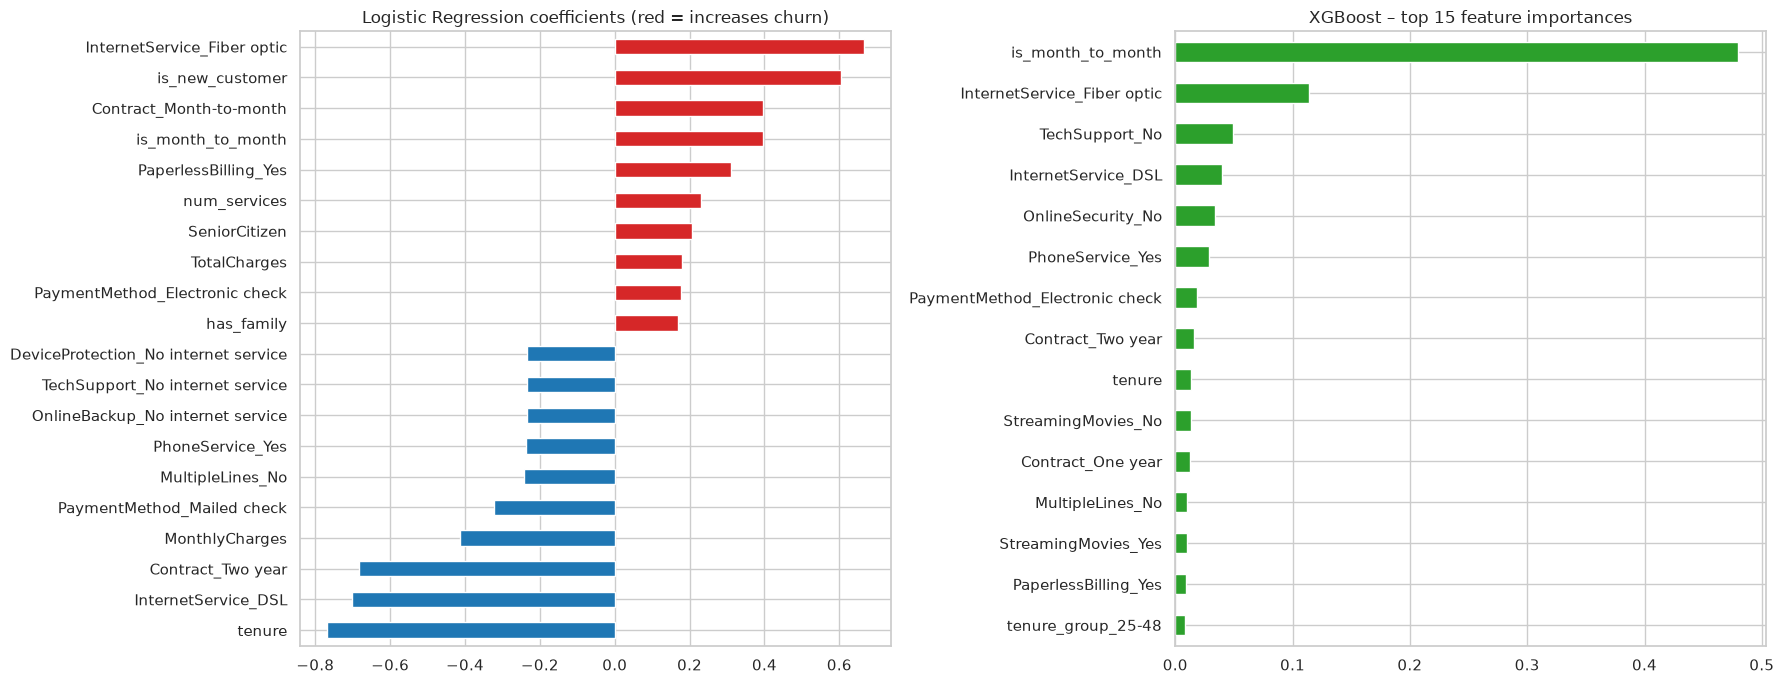

In [17]:
lr = fitted["LogisticRegression"]
names = lr.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
xgb = fitted["XGBoost"]
imp = pd.Series(xgb.named_steps["model"].feature_importances_,
                index=xgb.named_steps["preprocess"].get_feature_names_out()).nlargest(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot.barh(ax=axes[0], color=np.where(top > 0, "tab:red", "tab:blue"))
axes[0].set_title("Logistic Regression coefficients (red = increases churn)")
imp.plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title("XGBoost – top 15 feature importances")
plt.tight_layout()
plt.show()

Consistent with the EDA: **contract type** (month-to-month), **short tenure / new customer**,
**fiber optic** and electronic-check payment increase churn risk; long contracts, long tenure,
online security and tech support reduce it. Several engineered features
(`is_month_to_month`, `is_new_customer`, `tenure_group`) appear among the top drivers.

## 5. MLflow tracking
One run per model: hyperparameters, preprocessing parameters (imputation, scaling, encoding,
resampling), CV and test metrics, the confusion matrix / ROC figures and the fitted pipeline.

In [18]:
for name in MODEL_NAMES:
    cm = ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test, display_labels=["Stay", "Churn"],
                                               cmap="Blues", colorbar=False)
    cv_metrics = best_strategy.loc[name, ["precision", "recall", "f1", "roc_auc"]]
    metrics = {**{f"cv_{k}": v for k, v in cv_metrics.items()},
               **{f"test_{k}": v for k, v in test_results.loc[name, ["precision", "recall", "f1", "roc_auc"]].items()}}
    log_run(f"{name}_{best_strategy.loc[name, 'strategy']}", fitted[name], metrics,
            params={"imbalance_strategy": best_strategy.loc[name, "strategy"]},
            figures={"confusion_matrix": cm.figure_, "roc_curves": roc_fig},
            tags={"stage": "baseline", "with_cluster": "false"})
    plt.close(cm.figure_)

# Lighter runs (metrics only) for every model x strategy combination
for _, row in imbalance.iterrows():
    with mlflow.start_run(run_name=f"cv_{row['model']}_{row['strategy']}"):
        mlflow.log_params({"model": row["model"], "imbalance_strategy": row["strategy"]})
        mlflow.log_metrics({f"cv_{m}": row[m] for m in ["precision", "recall", "f1", "roc_auc"]})
        mlflow.set_tag("stage", "imbalance_comparison")
print("Runs logged to MLflow experiment 'tele-cluster-classification'")

Runs logged to MLflow experiment 'tele-cluster-classification'


In [19]:
mlflow.search_runs(filter_string="tags.stage = 'baseline'",
                   order_by=["metrics.test_f1 DESC"])[
    ["tags.mlflow.runName", "metrics.cv_f1", "metrics.test_precision", "metrics.test_recall",
     "metrics.test_f1", "metrics.test_roc_auc"]].round(3)

,tags.mlflow.runName,metrics.cv_f1,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc
0,SVM_class_weight,0.630,0.533,0.769,0.629,0.826
1,LogisticRegression_random_oversampling,0.631,0.519,0.780,0.623,0.841
2,XGBoost_random_oversampling,0.629,0.536,0.739,0.621,0.835
3,RandomForest_class_weight,0.614,0.561,0.634,0.595,0.826
4,DecisionTree_smote,0.506,0.509,0.511,0.510,0.671


## Summary
- Without rebalancing, recall ≈ 0.5: half of the churners are missed.
- `class_weight` / oversampling / SMOTE (fitted on training data only) raise recall to
  ≈ 0.75–0.80 and improve F1.
- Best models: Logistic Regression, SVM and XGBoost (test F1 ≈ 0.62–0.63, ROC-AUC ≈ 0.83–0.84).
- Main churn drivers: month-to-month contract, short tenure, fiber optic, electronic check,
  no online security / tech support.